In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

# If running from the notebooks directory, move to project root.
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

CLEANED_DATA_PATH = (
    PROJECT_ROOT / "data" / "processed" / "city_day_cleaned.csv"
)

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

if not CLEANED_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cleaned dataset not found: {CLEANED_DATA_PATH}\n"
        "Update CLEANED_DATA_PATH to match your saved CSV."
    )

df = pd.read_csv(CLEANED_DATA_PATH, parse_dates=["Date"])

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Cities:", df["City"].nunique())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

display(df.head())

Dataset loaded successfully
Shape: (29531, 16)
Cities: 26
Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,58.37,107.96,0.92,18.22,17.15,14.5,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,58.37,107.96,0.97,15.69,16.46,14.5,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,58.37,107.96,17.40,19.30,29.70,14.5,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,58.37,107.96,1.70,18.48,17.97,14.5,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,58.37,107.96,22.10,21.42,37.76,14.5,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [2]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Quarter"] = df["Date"].dt.quarter

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    return "Post-Monsoon"

df["Season"] = df["Month"].apply(get_season)

display(df[["Date", "Year", "Month_Name", "Quarter", "Season"]].head())

,Date,Year,Month_Name,Quarter,Season
0,2015-01-01,2015,January,1,Winter
1,2015-01-02,2015,January,1,Winter
2,2015-01-03,2015,January,1,Winter
3,2015-01-04,2015,January,1,Winter
4,2015-01-05,2015,January,1,Winter


In [3]:
aqi_stats = df["AQI"].describe().to_frame("AQI")

aqi_stats.loc["missing_count"] = df["AQI"].isna().sum()
aqi_stats.loc["missing_percent"] = (
    df["AQI"].isna().mean() * 100
)

display(aqi_stats.round(2))

aqi_stats.to_csv(TABLES_DIR / "overall_aqi_statistics.csv")

,AQI
count,24850.00
mean,166.46
std,140.70
min,13.00
25%,81.00
50%,118.00
75%,208.00
max,2049.00
missing_count,4681.00
missing_percent,15.85


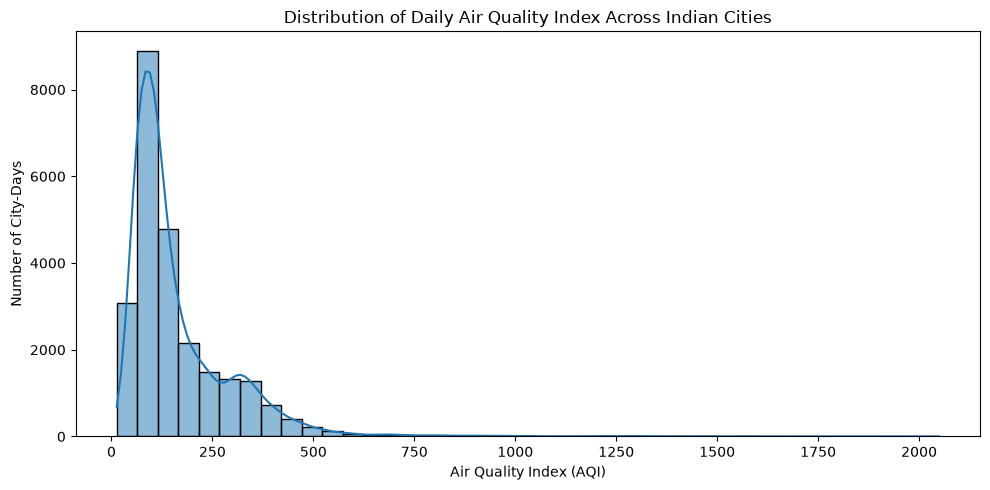

In [4]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="AQI",
    bins=40,
    kde=True
)

plt.title("Distribution of Daily Air Quality Index Across Indian Cities")
plt.xlabel("Air Quality Index (AQI)")
plt.ylabel("Number of City-Days")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "aqi_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,City,Average_AQI,Median_AQI,Available_Records
0,Ahmedabad,452.12,384.5,1334
10,Delhi,259.49,257.0,1999
21,Patna,240.78,215.0,1459
12,Gurugram,225.12,208.0,1453
19,Lucknow,217.97,198.0,1893
23,Talcher,172.89,128.5,698
16,Jorapokhar,159.25,133.0,771
6,Brajrajnagar,150.28,122.0,713
18,Kolkata,140.57,94.0,754
13,Guwahati,140.11,98.0,495


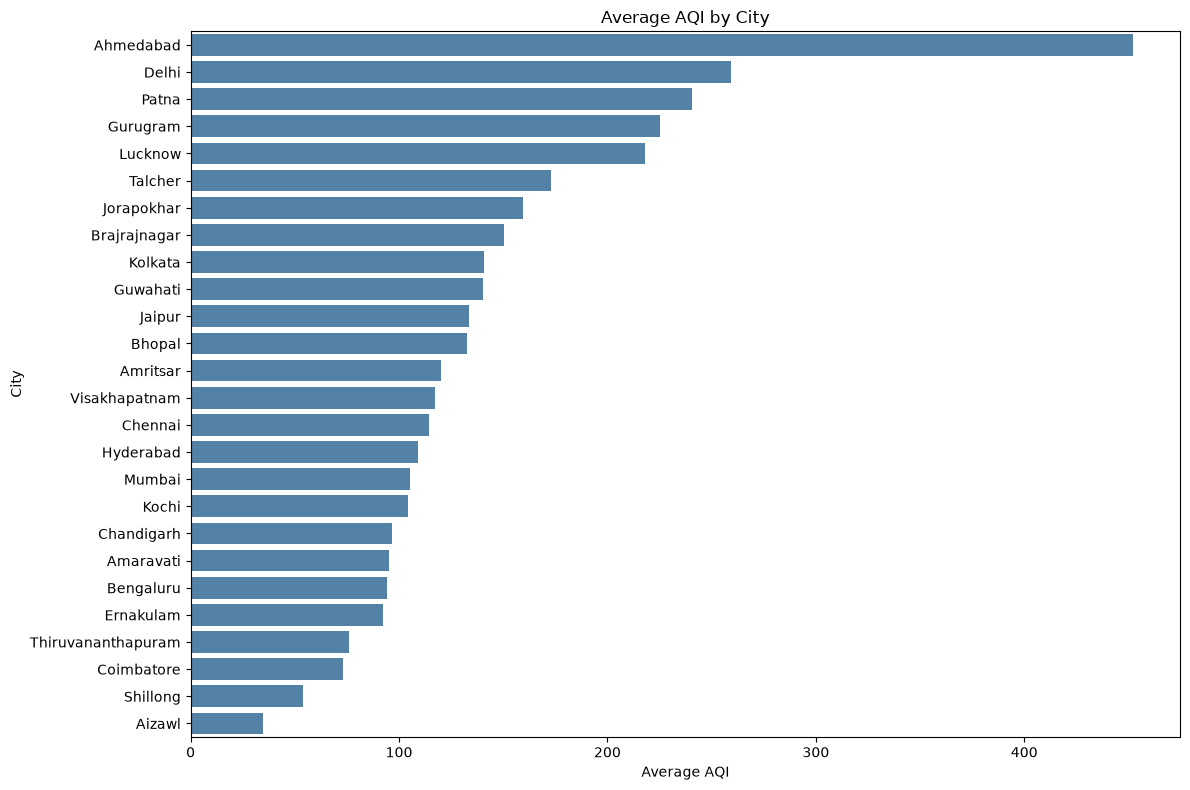

In [5]:
city_aqi = (
    df.groupby("City", as_index=False)
    .agg(
        Average_AQI=("AQI", "mean"),
        Median_AQI=("AQI", "median"),
        Available_Records=("AQI", "count")
    )
    .dropna(subset=["Average_AQI"])
    .sort_values("Average_AQI", ascending=False)
)

display(city_aqi.round(2))

city_aqi.to_csv(
    TABLES_DIR / "average_aqi_by_city.csv",
    index=False
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=city_aqi,
    x="Average_AQI",
    y="City",
    color="steelblue"
)

plt.title("Average AQI by City")
plt.xlabel("Average AQI")
plt.ylabel("City")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "average_aqi_by_city.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Year,Average_AQI,Median_AQI,Available_Records
0,2015,212.46,175.0,1827
1,2016,197.15,149.0,2573
2,2017,181.47,129.0,3234
3,2018,182.68,124.0,5724
4,2019,156.52,109.0,7071
5,2020,113.52,93.0,4421


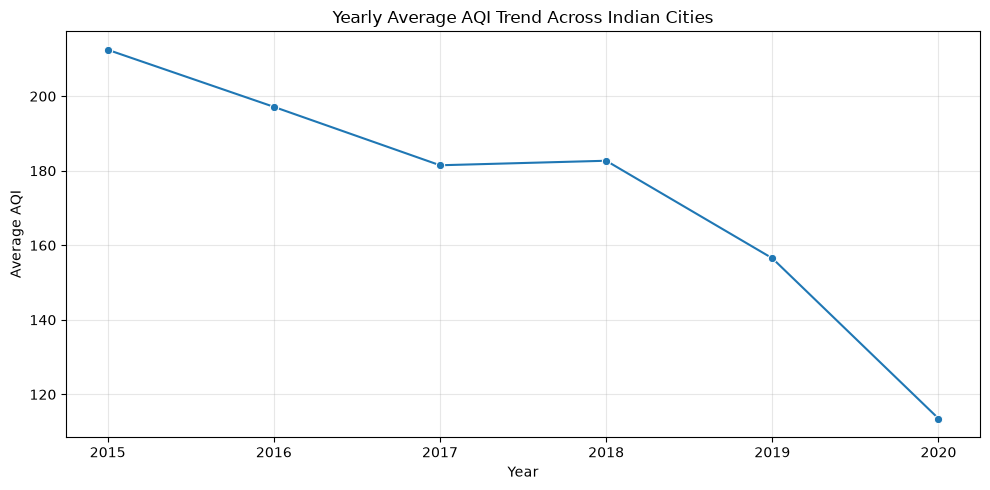

In [6]:
yearly_aqi = (
    df.groupby("Year", as_index=False)
    .agg(
        Average_AQI=("AQI", "mean"),
        Median_AQI=("AQI", "median"),
        Available_Records=("AQI", "count")
    )
)

display(yearly_aqi.round(2))

yearly_aqi.to_csv(
    TABLES_DIR / "yearly_aqi_trend.csv",
    index=False
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_aqi,
    x="Year",
    y="Average_AQI",
    marker="o"
)

plt.title("Yearly Average AQI Trend Across Indian Cities")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.xticks(yearly_aqi["Year"].astype(int))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "yearly_aqi_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Season,Average_AQI,Median_AQI,Available_Records
3,Winter,220.61,171.0,6243
2,Summer,147.67,115.0,7069
0,Monsoon,115.56,89.0,7713
1,Post-Monsoon,215.47,154.0,3825


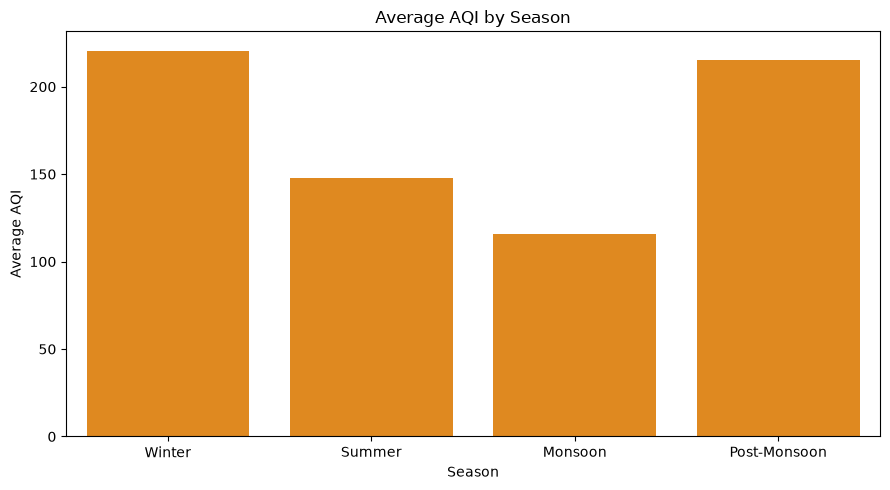

In [7]:
season_order = [
    "Winter",
    "Summer",
    "Monsoon",
    "Post-Monsoon"
]

seasonal_aqi = (
    df.groupby("Season", as_index=False)
    .agg(
        Average_AQI=("AQI", "mean"),
        Median_AQI=("AQI", "median"),
        Available_Records=("AQI", "count")
    )
)

seasonal_aqi["Season"] = pd.Categorical(
    seasonal_aqi["Season"],
    categories=season_order,
    ordered=True
)

seasonal_aqi = seasonal_aqi.sort_values("Season")

display(seasonal_aqi.round(2))

seasonal_aqi.to_csv(
    TABLES_DIR / "seasonal_aqi_analysis.csv",
    index=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=seasonal_aqi,
    x="Season",
    y="Average_AQI",
    color="darkorange"
)

plt.title("Average AQI by Season")
plt.xlabel("Season")
plt.ylabel("Average AQI")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "seasonal_aqi_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Month,Average_AQI,Median_AQI,Available_Records
0,1,231.67,183.0,2141
1,2,202.91,149.5,2078
2,3,164.74,124.0,2327
3,4,143.36,111.0,2295
4,5,135.49,111.0,2447
5,6,120.20,96.0,2344
6,7,111.85,86.0,1836
7,8,113.61,85.0,1776
8,9,115.19,88.0,1757
9,10,188.61,130.0,1889


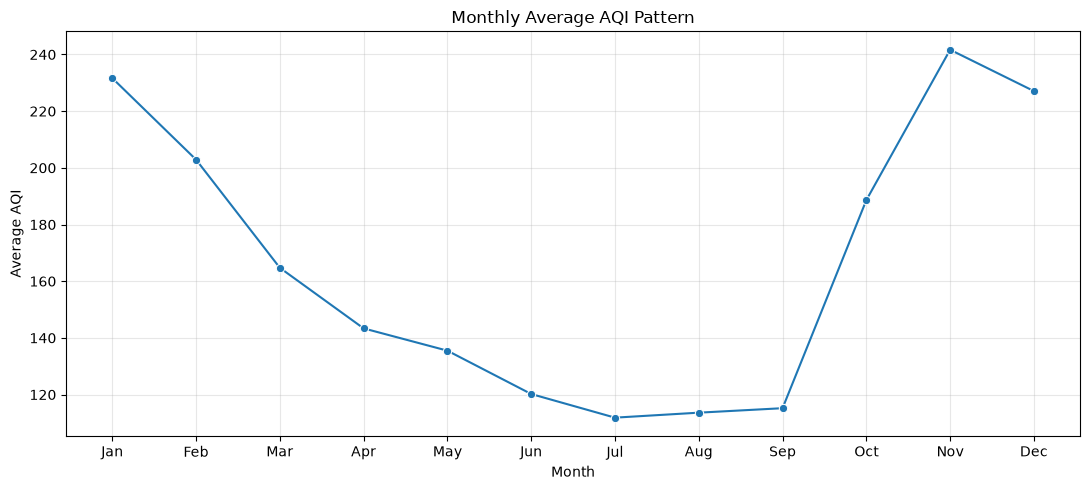

In [8]:
monthly_aqi = (
    df.groupby("Month", as_index=False)
    .agg(
        Average_AQI=("AQI", "mean"),
        Median_AQI=("AQI", "median"),
        Available_Records=("AQI", "count")
    )
)

display(monthly_aqi.round(2))

monthly_aqi.to_csv(
    TABLES_DIR / "monthly_aqi_analysis.csv",
    index=False
)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=monthly_aqi,
    x="Month",
    y="Average_AQI",
    marker="o"
)

plt.title("Monthly Average AQI Pattern")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "monthly_aqi_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
PM2.5,1.00,0.57,0.41,0.35,0.35,0.19,0.09,0.11,0.16,0.03,0.13,0.11,0.66
PM10,0.57,1.00,0.42,0.35,0.40,0.13,0.04,0.18,0.20,0.02,0.13,0.07,0.50
NO,0.41,0.42,1.00,0.45,0.76,0.12,0.20,0.16,0.02,0.04,0.13,0.06,0.45
NO2,0.35,0.35,0.45,1.00,0.57,0.12,0.38,0.39,0.30,0.04,0.31,0.17,0.53
NOx,0.35,0.40,0.76,0.57,1.00,0.08,0.23,0.20,0.09,0.05,0.18,0.07,0.47
NH3,0.19,0.13,0.12,0.12,0.08,1.00,-0.04,-0.10,0.08,-0.00,0.00,-0.04,0.09
CO,0.09,0.04,0.20,0.38,0.23,-0.04,1.00,0.51,0.06,0.06,0.30,0.16,0.68
SO2,0.11,0.18,0.16,0.39,0.20,-0.10,0.51,1.00,0.16,0.03,0.28,0.21,0.49
O3,0.16,0.20,0.02,0.30,0.09,0.08,0.06,0.16,1.00,0.03,0.15,0.07,0.20
Benzene,0.03,0.02,0.04,0.04,0.05,-0.00,0.06,0.03,0.03,1.00,0.69,0.09,0.05


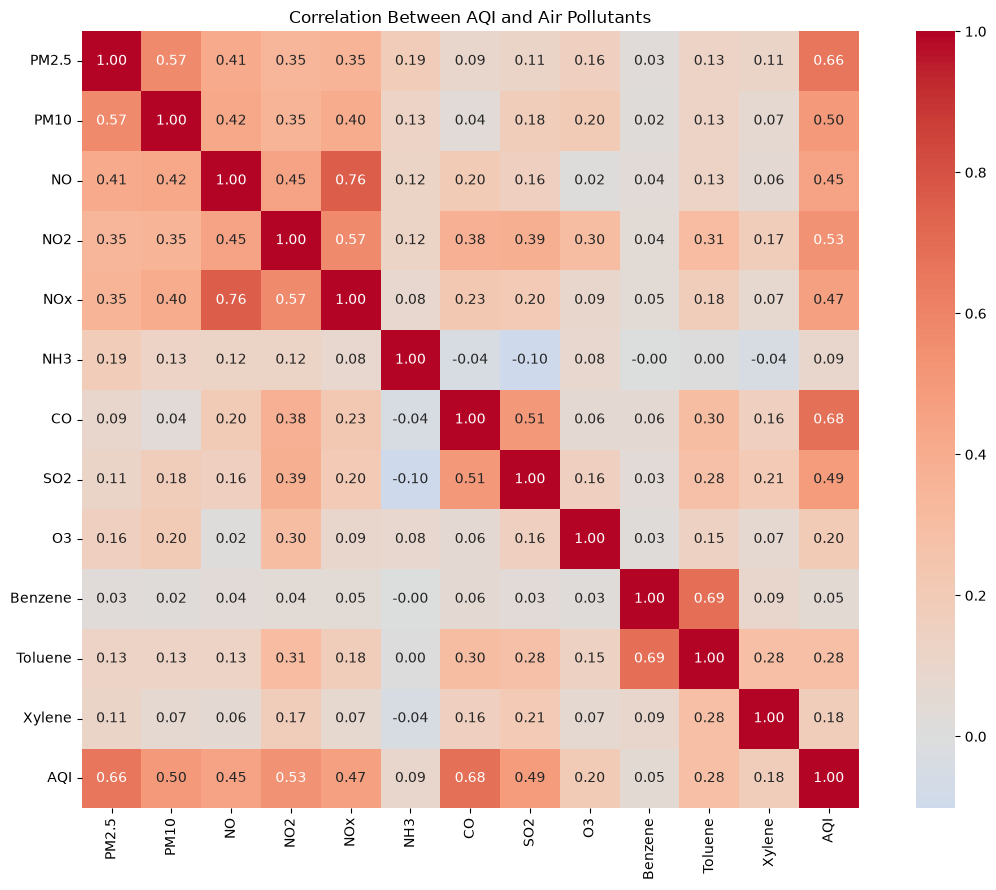

In [9]:
pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3",
    "Benzene", "Toluene", "Xylene", "AQI"
]

available_pollutants = [
    col for col in pollutants if col in df.columns
]

correlation_matrix = df[available_pollutants].corr(
    method="pearson",
    min_periods=30
)

display(correlation_matrix.round(2))

correlation_matrix.to_csv(
    TABLES_DIR / "pollutant_correlation_matrix.csv"
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlation Between AQI and Air Pollutants")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "pollutant_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
summary = {
    "Total_Rows": len(df),
    "Total_Columns": len(df.columns),
    "Unique_Cities": df["City"].nunique(),
    "Start_Date": df["Date"].min(),
    "End_Date": df["Date"].max(),
    "Available_AQI_Records": df["AQI"].notna().sum(),
    "Missing_AQI_Records": df["AQI"].isna().sum(),
    "Average_AQI": df["AQI"].mean(),
    "Median_AQI": df["AQI"].median(),
    "Highest_AQI": df["AQI"].max(),
    "Lowest_AQI": df["AQI"].min()
}

eda_summary = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

display(eda_summary.round(2))

eda_summary.to_csv(
    TABLES_DIR / "eda_summary.csv",
    index=False
)

print("EDA completed.")
print("Figures saved to:", FIGURES_DIR)
print("Tables saved to:", TABLES_DIR)

,Metric,Value
0,Total_Rows,29531
1,Total_Columns,21
2,Unique_Cities,26
3,Start_Date,2015-01-01 00:00:00
4,End_Date,2020-07-01 00:00:00
5,Available_AQI_Records,24850
6,Missing_AQI_Records,4681
7,Average_AQI,166.463581
8,Median_AQI,118.0
9,Highest_AQI,2049.0


EDA completed.
Figures saved to: /Users/ashokreddy/india-air-pollution-analysis/outputs/figures
Tables saved to: /Users/ashokreddy/india-air-pollution-analysis/outputs/tables
